# COSMOS-AI — deep-learning experiments on real and simulated data

This notebook walks through the COSMOS-AI layer on the datasets that were actually downloaded.
Every number it prints is either computed here or read from `outputs/benchmarks/`, where the
benchmark scripts wrote it. Evidence classes, as in the research design:

* **REAL**: ESA-ADB, OPSSAT-AD, SpotGEO, CelesTrak, ESA recovered debris.
* **SYNTHETIC / SIM**: COSMOS telemetry simulator, COSMOS frame pairs, COSMOS re-entry propagator.

Heavy training is not repeated here: the notebook loads the checkpoints the benchmarks saved.
It retrains only the small models where that takes seconds.

In [1]:
import sys, os, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
os.environ.setdefault("COSMOS_DEVICE", "cpu")      # the notebook runs on CPU
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cosmos
from cosmos.ai.data import download
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

def table(path, **kw):
    # a benchmark table, or a clear note when that benchmark has not been run yet
    if not os.path.isfile(path):
        print(f"not run yet: {path} is missing (run the benchmark, then python -m cosmos.ai.report)")
        return pd.DataFrame()
    return pd.read_csv(path, **kw)

print("cosmos", cosmos.__version__)
download.status()

cosmos 1.1.0


,dataset,status,class,files,MB,licence
0,opssat_ad,downloaded,REAL,7,18.6,cc-by-4.0
1,esa_adb,downloaded,REAL,6,11089.3,not stated in the Zenodo record; CC BY 3.0 IGO...
2,cosmos_synthetic_telemetry,generated,SYNTHETIC,1,35.2,
3,spotgeo,downloaded,REAL,4,4035.0,cc-by-4.0
4,spark,not downloaded,SYNTHETIC renders + Zero-G lab images (per the...,0,0.0,
5,spacesense_bench,inspection sample only (1 of 136 archives),SYNTHETIC (Unreal Engine 5 renders),1,487.3,cc-by-nc-4.0 (Hugging Face card); GitHub repo ...
6,cosmos_synthetic_vision,generated,SYNTHETIC,2,0.5,generated by this project
7,celestrak,downloaded,REAL,15,21.2,"CelesTrak usage policy; public, no credentials..."
8,reentry_historical,downloaded (public parts only),REAL,2,0.2,
9,reentry_simulated,generated,SIM,4,63.6,


## 1. Telemetry — ESA-ADB under the official protocol

The archives (Zenodo 12528696) were MD5-checked. The official benchmark's preprocessing was
re-implemented and checked against a literal port of the official pandas code (`tests/test_ai.py`).
The result is the official 30 s grid for Mission 1: 7 years for training and 7 years for testing.

In [2]:
from cosmos.ai.data.preprocess_telemetry import load_esa_split, official_test_labels, ESA_PROTOCOL
te = load_esa_split(1, "test")
lab = official_test_labels(1, te)
lab = lab[lab.Channel.isin(ESA_PROTOCOL[1]["target"])]
print(f"test grid {te.n:,} x {len(te.channels)} channels from {te.timestamps()[0]} to {te.timestamps()[-1]}")
lab.groupby("ID").Category.first().value_counts()

test grid 7,364,161 x 76 channels from 2007-01-01 00:00:00 to 2014-01-01 00:00:00


Category
Anomaly       55
Rare Event    36
Name: count, dtype: int64

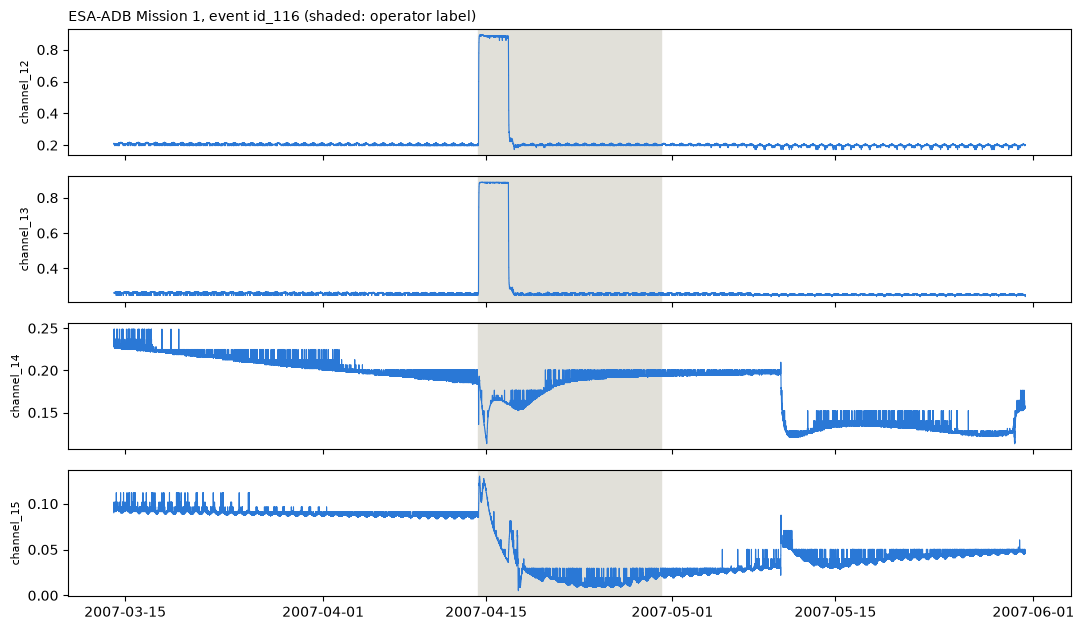

In [3]:
# one labelled event, the channels the operators marked, and the surrounding telemetry
ev = lab.groupby("ID").agg(s=("StartTime", "min"), e=("EndTime", "max"), cat=("Category", "first"),
                           n=("Channel", "nunique")).sort_values("n", ascending=False)
eid = ev[ev.cat == "Anomaly"].index[0]; s, e = ev.loc[eid, "s"], ev.loc[eid, "e"]
chans = sorted(lab[lab.ID == eid].Channel.unique(), key=lambda c: int(c.split("_")[1]))[:4]
i0, i1 = te.index_of(s - (e - s) * 2), te.index_of(e + (e - s) * 2)
ts = te.timestamps()[i0:i1]
fig, axes = plt.subplots(len(chans), 1, figsize=(11, 1.6 * len(chans)), sharex=True)
for ax, c in zip(np.atleast_1d(axes), chans):
    ax.plot(ts, te.X[i0:i1, te.channel_index([c])[0]], lw=0.8, color="#2a78d6")
    ax.axvspan(s, e, color="#e1e0d9"); ax.set_ylabel(c, fontsize=8)
axes[0].set_title(f"ESA-ADB Mission 1, event {eid} (shaded: operator label)", loc="left", fontsize=10)
plt.tight_layout()

### Results: every encoder through the same calibrators

Each arm uses the same steps:

1. Train on nominal windows of the training half.
2. Select the calibrator on the last 9 months of the training half, by cross-fitting.
3. Score the test half once, with the vendored official metric code.

The vertical line in the figure is the best value published in DMLR 2026.

In [4]:
t = table("../outputs/benchmarks/telemetry_esa_adb/summary_table.csv")
cols = ["mission", "channels", "encoder", "calibrator", "n_seeds", "anomaly_and_rare/EW_F0.5|mean",
        "anomaly_and_rare/EW_F0.5|std", "anomaly_and_rare/EW_precision|mean", "anomaly_and_rare/EW_recall|mean",
        "anomaly_and_rare/channel_F0.5|mean", "false_alarms_per_year|mean"]
t if t.empty else t[t.channels == "target"][cols].sort_values(["mission", "anomaly_and_rare/EW_F0.5|mean"], ascending=[True, False]).round(3)

,mission,channels,encoder,calibrator,n_seeds,anomaly_and_rare/EW_F0.5|mean,anomaly_and_rare/EW_F0.5|std,anomaly_and_rare/EW_precision|mean,anomaly_and_rare/EW_recall|mean,anomaly_and_rare/channel_F0.5|mean,false_alarms_per_year|mean
34,1,target,tcn+tc,conformal_bh_rolling,3,0.318,0.215,0.674,0.103,0.073,0.571
31,1,target,tcn,conformal_bh_rolling,3,0.168,0.176,0.397,0.051,0.040,1.333
28,1,target,persistence,conformal_bh_rolling,1,0.097,NaN,0.667,0.022,0.016,0.143
22,1,target,patchtst,conformal_bh_rolling,3,0.095,0.043,0.409,0.084,0.042,14.094
14,1,target,ar8,threshold,1,0.088,NaN,0.074,0.396,0.213,64.422
12,1,target,ar8,conformal_bh,1,0.074,NaN,0.061,0.462,0.219,91.562
25,1,target,patchtst+tc,conformal_bh_rolling,3,0.071,0.001,0.162,0.022,0.019,1.476
32,1,target,tcn,threshold,3,0.069,0.011,0.058,0.256,0.124,54.852
13,1,target,ar8,conformal_bh_rolling,1,0.068,NaN,0.056,0.473,0.213,103.847
35,1,target,tcn+tc,threshold,3,0.062,0.020,0.052,0.289,0.147,76.040


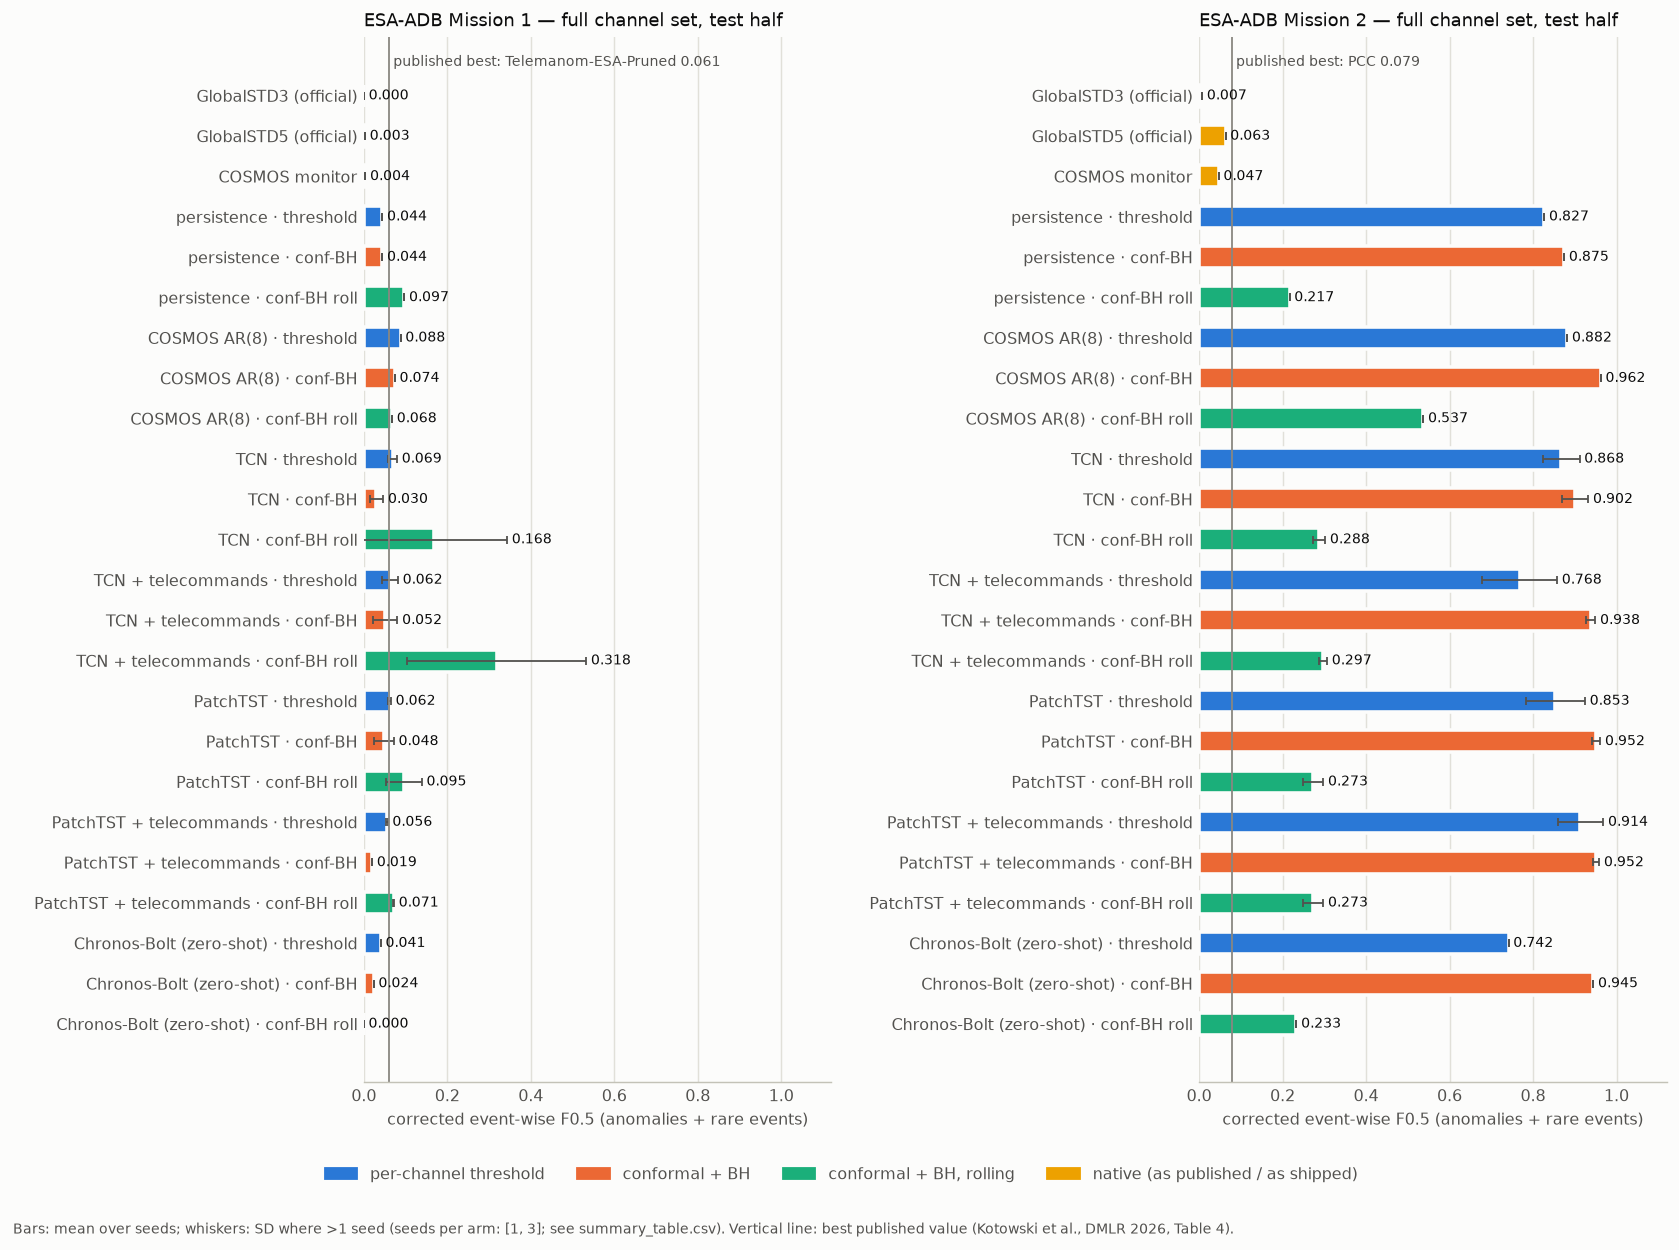

In [5]:
from IPython.display import Image
Image("../outputs/benchmarks/figures/esa_adb_target_ew_f05.png")

### Uncertainty and explanation: per-channel conformal p-values at an alarm

The alarm rule is the explanation. Each channel's normalised forecast error gets a conformal
p-value against the nominal calibration scores, Benjamini-Hochberg runs across channels, and the
rejected channels are the ones reported. The scores below are the saved test scores of the
PatchTST arm (seed 0).

In [6]:
import glob
from cosmos.ai.uncertainty import conformal_pvalues
from cosmos.ai.explain import channel_evidence
from cosmos.ai.telemetry.forecasting import MissionData
runs = sorted(glob.glob("../outputs/experiments/*esa_m2_target_patchtst_s0_s0"))
if runs and os.path.isfile(os.path.join(runs[-1], "scores_test.npy")):
    D = MissionData(2)
    S_cal = np.load(os.path.join(runs[-1], "scores_cal.npy")); S_te = np.load(os.path.join(runs[-1], "scores_test.npy"), mmap_mode="r")
    a, b = D.p["cal"]
    cal = [np.sort(S_cal[:, c][(D.Ltr[a:b, c] == 0) & np.isfinite(S_cal[:, c])]) for c in range(S_cal.shape[1])]
    labm2 = official_test_labels(2, D.test); labm2 = labm2[labm2.Channel.isin(D.channels)]
    eid = labm2.ID.iloc[0]; row = labm2[labm2.ID == eid]
    k = D.test.index_of(row.StartTime.min()) + 5
    p = np.array([conformal_pvalues(cal[c], np.nan_to_num(S_te[k:k+1, c], nan=-1))[0] for c in range(len(cal))])
    ev = pd.DataFrame(channel_evidence(p, D.channels, q=1e-4)).head(8)
    ev["labelled_by_operators"] = ev.channel.isin(row.Channel)
    print(f"event {eid} ({row.Category.iloc[0]}), {D.test.timestamps()[k]}")
    display(ev)
else:
    print("PatchTST M2 seed 0 scores not found — run the ESA benchmark first")

event id_11 (Rare Event), 2003-05-23 01:29:24


,channel,p_value,rejected,labelled_by_operators
0,channel_83,0.000551,False,True
1,channel_84,0.000557,False,True
2,channel_77,0.000572,False,True
3,channel_85,0.000603,False,True
4,channel_79,0.000624,False,True
5,channel_72,0.000635,False,True
6,channel_76,0.000929,False,True
7,channel_78,0.000951,False,True


## 2. Telemetry — OPSSAT-AD (official split, 5 seeds)

anomaly  anomalous  nominal
train                      
test           113      416
train          321     1273


Text(0.0, 1.0, 'anomalous fragment 1 (CADC0872)')

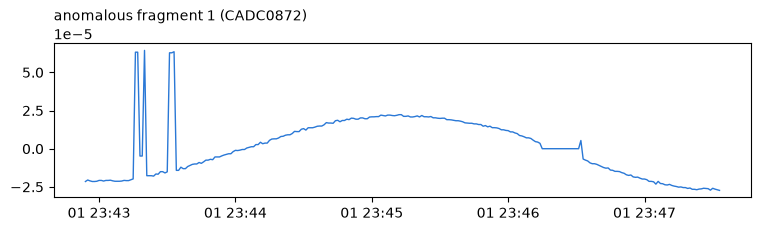

In [7]:
from cosmos.ai.data.preprocess_telemetry import load_opssat_ad
d = load_opssat_ad(); f = d["features"]
print(pd.crosstab(f.train.map({1: "train", 0: "test"}), f.anomaly.map({1: "anomalous", 0: "nominal"})))
g = d["segments"]; seg = g[g.segment == f[f.anomaly == 1].index[0]]
plt.figure(figsize=(9, 2)); plt.plot(seg.timestamp, seg.value, lw=1, color="#2a78d6"); plt.title(f"anomalous fragment {seg.segment.iloc[0]} ({seg.channel.iloc[0]})", loc="left", fontsize=10)

In [8]:
s = table("../outputs/benchmarks/telemetry_opssat/summary_official.csv")
s[s.train_frac == 1.0][["model", "n_seeds", "f1_mean", "f1_std", "auc_pr_mean", "auc_pr_std", "mcc_mean", "ece_mean"]].sort_values("auc_pr_mean", ascending=False).round(3)

,model,n_seeds,f1_mean,f1_std,auc_pr_mean,auc_pr_std,mcc_mean,ece_mean
17,cnn,5,0.939,0.015,0.987,0.003,0.922,0.051
20,hybrid,5,0.949,0.009,0.986,0.002,0.936,0.013
19,fcnn,5,0.937,0.008,0.980,0.002,0.920,0.016
23,random_forest,5,0.909,0.004,0.964,0.001,0.887,0.020
25,xgboost,5,0.911,0.008,0.961,0.002,0.889,0.019
22,logreg,1,0.863,NaN,0.957,NaN,0.832,0.034
16,chronos:amazon/chronos-bolt-small,5,0.889,0.000,0.955,0.000,0.862,0.021
24,transformer,5,0.898,0.016,0.948,0.004,0.873,0.030
15,adaboost,5,0.838,0.000,0.925,0.000,0.802,0.316
18,cosmos_robust_z,1,0.436,NaN,0.471,NaN,0.386,NaN


In [9]:
table("../outputs/benchmarks/telemetry_opssat/paired_comparisons.csv").round(4)

,A,B,metric,diff,ci_low,ci_high,p_two_sided
0,hybrid,fcnn,AUC-PR (seed-averaged scores),0.0059,0.0004,0.0127,0.036
1,hybrid,fcnn,F1 @ 0.5 (seed-averaged scores),0.0147,-0.0080,0.0407,0.164
2,hybrid,xgboost,AUC-PR (seed-averaged scores),0.0254,0.0078,0.0460,0.002
3,hybrid,xgboost,F1 @ 0.5 (seed-averaged scores),0.0471,0.0157,0.0821,0.002
4,fcnn,xgboost,AUC-PR (seed-averaged scores),0.0195,0.0022,0.0388,0.023
5,fcnn,xgboost,F1 @ 0.5 (seed-averaged scores),0.0324,0.0041,0.0628,0.034
6,hybrid,chronos:amazon/chronos-bolt-small,AUC-PR (seed-averaged scores),0.0316,0.0134,0.0558,0.000
7,hybrid,chronos:amazon/chronos-bolt-small,F1 @ 0.5 (seed-averaged scores),0.0665,0.0290,0.1095,0.000
8,cnn,fcnn,AUC-PR (seed-averaged scores),0.0081,-0.0059,0.0259,0.277
9,cnn,fcnn,F1 @ 0.5 (seed-averaged scores),0.0105,-0.0204,0.0438,0.504


### Explanation: Integrated Gradients on the hybrid model, with a randomisation check

The hybrid checkpoint (seed 0) is loaded and Integrated Gradients are computed over the time axis
of one test fragment. A faithful attribution must change when the weights are re-initialised
(Adebayo et al. 2018), so a low rank correlation passes the check.

P(anomalous) = 0.9997 | completeness gap 0.001 | randomisation rank corr 0.908
sanity check: FAIL - the attribution barely depends on the learned weights (it mostly follows the input's magnitude), so this IG map is NOT evidence of what the model uses


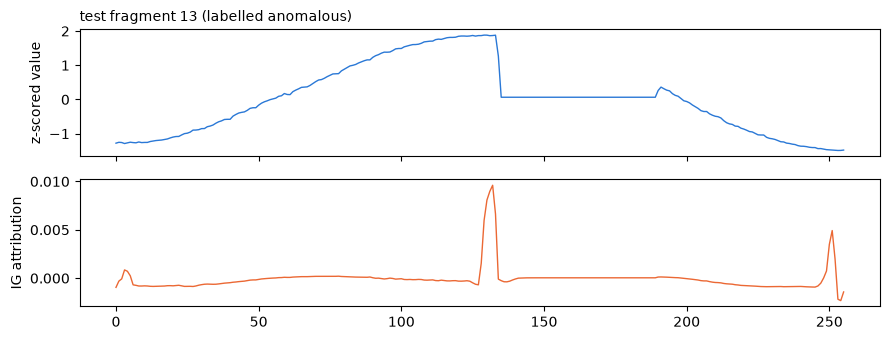

In [10]:
import torch
from cosmos.ai.telemetry.opssat import OpssatData
from cosmos.ai.telemetry.models import build_classifier
from cosmos.ai.explain import integrated_gradients, completeness_gap, randomisation_check
from sklearn.preprocessing import StandardScaler
D = OpssatData(256); tr, va, te_idx = D.split("official")
ck = sorted(glob.glob("../outputs/experiments/*opssat_hybrid_official_f100_s0/checkpoints/best.pt"))
if ck:
    net = build_classifier("hybrid", in_ch=3, n_features=18); net.load_state_dict(torch.load(ck[-1], map_location="cpu")["state_dict"]); net.eval()
    F = torch.tensor(StandardScaler().fit(D.F[tr]).transform(D.F), dtype=torch.float32)
    i = te_idx[D.y[te_idx] == 1][0]
    x = torch.tensor(D.X[i:i+1]); fi = F[i:i+1]
    f = lambda z: torch.sigmoid(net(z, fi.expand(len(z), -1), None))
    att = integrated_gradients(f, x, steps=64)
    rho = randomisation_check(net, lambda m, z: torch.sigmoid(m(z, fi.expand(len(z), -1), None)), x)
    print("P(anomalous) =", round(float(f(x)), 4), "| completeness gap", round(completeness_gap(f, x, att), 4),
          "| randomisation rank corr", round(rho, 3))
    print("sanity check:", "PASS" if rho < 0.5 else "FAIL - the attribution barely depends on the learned weights "
          "(it mostly follows the input's magnitude), so this IG map is NOT evidence of what the model uses")
    fig, ax = plt.subplots(2, 1, figsize=(9, 3.5), sharex=True)
    ax[0].plot(D.X[i, 0], color="#2a78d6", lw=1); ax[0].set_ylabel("z-scored value")
    ax[1].plot(att[0, 0].numpy(), color="#eb6834", lw=1); ax[1].set_ylabel("IG attribution")
    ax[0].set_title(f"test fragment {D.feats.index[i]} (labelled anomalous)", loc="left", fontsize=10); plt.tight_layout()
else:
    print("hybrid checkpoint not found")

## 3. Telemetry — the learned monitor inside the original COSMOS chain (SYNTHETIC)

`LearnedHealthMonitor` has the same interface as the classical `HealthMonitor`. The benchmark ran
both monitors on 240 faulted and 40 fault-free simulated runs (seed sets 5-9, scored once, after
seed sets 0-4 had been used to fix the design). These are simulator results only.

In [11]:
table("../outputs/benchmarks/telemetry_cosmos_synthetic/heldout/summary_by_seed.csv").groupby("monitor").mean(numeric_only=True).round(3).drop(columns="seed_set")

,precision,recall,f1,false_alarms_on_nominal,median_delay_samples,localisation_accuracy,seconds_per_record
monitor,,,,,,,
classical_ewma,1.000,0.715,0.834,0.0,622.1,0.83,0.009
learned_conformal,0.929,0.665,0.775,0.6,734.5,0.96,0.133


In [12]:
r_classic = cosmos.run_pipeline(faults={"Propulsion System": "leak"}, n_samples=300, seed=3)
r_learned = cosmos.run_pipeline(faults={"Propulsion System": "leak"}, n_samples=300, seed=3, backend="learned")
pd.DataFrame({"classical": r_classic.summary().value.values, "learned backend": r_learned.summary().value.values},
             index=r_classic.summary().quantity).head(10)

,classical,learned backend
quantity,,
telemetry samples,2880,2880
injected fault,Propulsion System (leak),Propulsion System (leak)
anomaly score (final),0.958,0.155
worst subsystem,Propulsion System,Propulsion System
health band,CRITICAL,WATCH
detection delay (min),316.5,380.5
break-up type,explosion,explosion
break-up altitude (km),82.0,88.8
P(fragmentation),0.63,0.027


## 4. Vision — SpotGEO (REAL) and COSMOS frame pairs (SYNTHETIC)

SpotGEO frames contain star streaks, clouds and a pointing drift between frames. The unchanged
COSMOS registration front end aligns the star field so that the GEO target stands out in the
difference image.

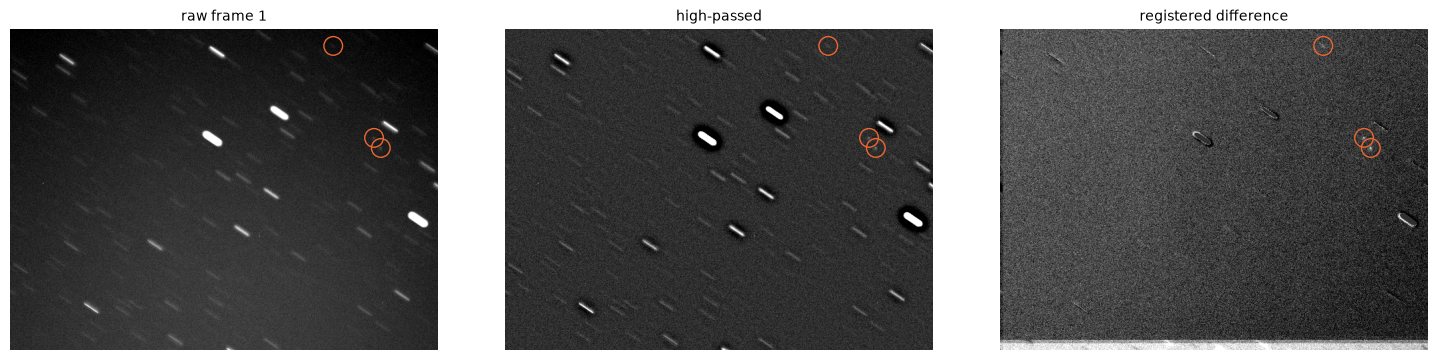

In [13]:
from cosmos.ai.vision import spotgeo as S
lab_sg = S.load_annotations("train"); seq = 31
X = S.load_cached("train", seq)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
F0 = S.read_frames("train", seq)[0]
for a, img, title in zip(ax, (F0, X[0, 1], X[0, 0]), ("raw frame 1", "high-passed", "registered difference")):
    lo, hi = np.percentile(img, [1, 99.7]); a.imshow(img, cmap="gray", vmin=lo, vmax=hi); a.set_title(title, fontsize=10); a.axis("off")
    c = lab_sg[seq][1]; a.scatter(c[:, 0], c[:, 1], s=180, facecolors="none", edgecolors="#eb6834")
plt.tight_layout()

In [14]:
v = table("../outputs/benchmarks/vision_spotgeo/summary.csv")
v if v.empty else v[[c for c in v.columns if c.split("|")[0] in ("model", "inputs", "train_frac", "n_seeds", "test_f1", "test_one_minus_f1", "test_precision", "test_recall", "latency_ms_per_sequence")]].round(4)

,model,inputs,train_frac,test_f1|mean,test_f1|std,test_one_minus_f1|mean,test_one_minus_f1|std,test_precision|mean,test_precision|std,test_recall|mean,test_recall|std,latency_ms_per_sequence|mean,latency_ms_per_sequence|std,n_seeds
0,classical COSMOS front end + DoG,diff,1.00,0.0838,NaN,0.9162,NaN,0.0485,NaN,0.3082,NaN,NaN,NaN,1
1,resnet18_pretrained,both,1.00,0.7646,0.0335,0.2354,0.0335,0.8618,0.0251,0.6872,0.0381,2.9082,0.3781,2
2,unet,both,0.10,0.5345,NaN,0.4655,NaN,0.7631,NaN,0.4113,NaN,1.8618,NaN,1
3,unet,both,0.25,0.6630,NaN,0.3370,NaN,0.8544,NaN,0.5417,NaN,2.1119,NaN,1
4,unet,both,1.00,0.7460,0.0053,0.2540,0.0053,0.8460,0.0049,0.6672,0.0088,1.7323,0.0377,3
5,unet,diff,1.00,0.6440,NaN,0.3560,NaN,0.7488,NaN,0.5650,NaN,1.5851,NaN,1
6,unet,raw,1.00,0.7507,NaN,0.2493,NaN,0.8806,NaN,0.6542,NaN,1.6997,NaN,1


official score on this sequence: {'precision': 1.0, 'recall': 1.0, 'f1': 1.0}


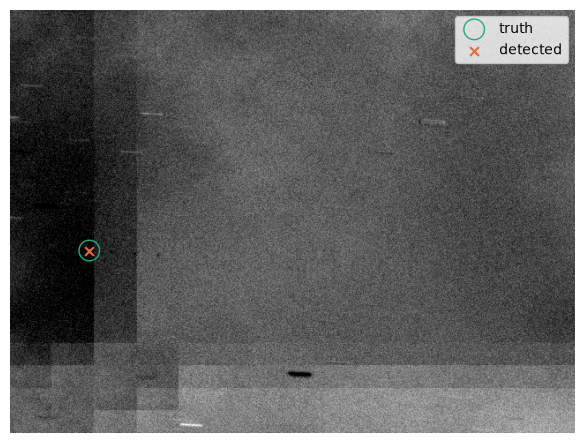

In [15]:
# the trained heat-map detector on one TEST sequence
from cosmos.ai.vision.heatmap import build, decode
from cosmos.ai.vision.train_spotgeo import to_input
ck = sorted(glob.glob("../outputs/experiments/*spotgeo_unet_both_f100_s0/checkpoints/best.pt"))
if ck:
    st = torch.load(ck[-1], map_location="cpu"); m = build("unet", 10, 5); m.load_state_dict(st["state_dict"]); m.eval()
    lab_te = S.load_annotations("test"); seq = 17; Xt = S.load_cached("test", seq)
    with torch.no_grad():
        dets = decode(m(torch.tensor(to_input(Xt, "both")[None])), st["threshold"])[0]
    pred = {seq: {f + 1: dets[f][:, :2] for f in range(5)}}
    print("official score on this sequence:", {k: round(v, 3) for k, v in S.score(pred, "test", [seq], lab_te).items() if k in ("precision", "recall", "f1")})
    plt.figure(figsize=(8, 5.5)); plt.imshow(Xt[0, 0], cmap="gray", vmin=-3, vmax=6)
    g = lab_te[seq][1]; plt.scatter(g[:, 0], g[:, 1], s=220, facecolors="none", edgecolors="#1baf7a", label="truth")
    plt.scatter(dets[0][:, 0], dets[0][:, 1], s=40, marker="x", color="#eb6834", label="detected"); plt.legend(); plt.axis("off")
else:
    print("SpotGEO heat-map checkpoint not found")

In [16]:
table("../outputs/benchmarks/vision_cosmos_synthetic/summary.csv").round(3)

,model,map50|mean,map50|std,map50_95|mean,map50_95|std,small_map50|mean,small_map50|std,map50_class_agnostic|mean,map50_class_agnostic|std,precision@conf|mean,precision@conf|std,recall@conf|mean,recall@conf|std,f1@conf|mean,f1@conf|std,mean_iou@conf|mean,mean_iou@conf|std,latency_ms_per_item|mean,latency_ms_per_item|std,params|mean,params|std,train_time_s|mean,train_time_s|std,n_seeds
0,heatmap-unet (COSMOS-AI),0.780,0.007,0.370,0.022,0.764,0.022,0.985,0.002,0.661,0.050,0.834,0.098,0.733,0.013,0.758,0.012,0.126,0.008,7790836.0,0.0,1558.797,13.939,3
1,tinyyolo (existing COSMOS),0.379,0.011,0.162,0.004,0.289,0.019,0.832,0.012,0.528,0.038,0.598,0.005,0.560,0.020,0.730,0.003,0.039,0.004,320313.0,0.0,131.157,42.017,3
2,"yolov8n (ultralytics, COCO-pretrained)",0.431,0.106,0.244,0.046,0.401,0.111,0.963,0.003,0.498,0.096,0.568,0.091,0.531,0.094,0.794,0.020,2.221,0.003,3138732.0,0.0,1732.137,117.910,3


## 5. Re-entry — a leakage-free landmark on the real catalogue

The population is every object in orbit on 2026-08-16. Its features are only what the 2026-08-16
snapshot knew; its outcome is the decay date in the 2026-10-24 snapshot, censored on 2026-10-23.
The splits are by launch.

In [17]:
from cosmos.ai.data.preprocess_catalogue import leakage_report
L = pd.read_csv("../data/feature3_reentry/derived/landmark_2026-08-16_to_2026-10-23.csv")
print(json.load(open("../data/feature3_reentry/derived/landmark_2026-08-16_to_2026-10-23_exclusions.json")))
print(leakage_report(L))
r = json.load(open("../outputs/benchmarks/reentry_landmark/results.json"))
pd.DataFrame({m: {k: v for k, v in x.items() if k in ("all/h68/auc_pr", "all/h30/auc_pr", "all/c_index", "all/h68/brier", "all/h68/ece")}
              for m, x in r["results"].items()}).T.round(4)

{'tau_snapshot_objects': 70288, 'in_orbit_at_tau': 34818, 'earth_orbiting': 34501, 'with_orbit_fields': 34166, 'launched_by_tau': 34166, 'missing_from_follow_snapshot': 0, 'decayed_before_tau_reported_late': 8, 'population_at_risk': 34158, 'events': 235, 'follow_up_days': 68}
{'no_gp_epoch_after_tau_day': True, 'no_event_at_or_before_tau': True, 'launch_groups_in_one_split': True, 'no_decay_field_in_features': True, 'censoring_time_constant': True}


,all/c_index,all/h30/auc_pr,all/h68/auc_pr,all/h68/brier,all/h68/ece
physics,0.9760,0.2538,0.1882,0.0056,0.0015
logreg,0.9902,0.5281,0.5272,0.0039,0.0017
xgboost,0.9973,0.7608,0.8213,0.0025,0.0022
xgboost_aft,0.9967,0.6582,0.8135,0.0026,0.0021
hazard_mlp,0.9957,0.6097,0.6877,0.0033,0.0024
hazard_mlp_nophys,0.9946,0.5874,0.6619,0.0033,0.0024


In [18]:
# uncertainty: label-conditional conformal sets cover the rare events, marginal sets do not
pd.DataFrame({m: {"marginal coverage (all)": c["marginal"]["coverage"], "marginal coverage (events)": c["marginal"]["coverage_on_events"],
                  "Mondrian coverage (events)": c["mondrian"]["coverage_events"], "Mondrian coverage (non-events)": c["mondrian"]["coverage_nonevents"]}
              for m, c in r["conformal_sets_h68"].items()}).T.round(3)

,marginal coverage (all),marginal coverage (events),Mondrian coverage (events),Mondrian coverage (non-events)
hazard_mlp,0.881,0.132,0.895,0.882
xgboost,0.911,0.000,0.974,0.916
xgboost_aft,0.901,0.000,0.921,0.905
physics,0.923,0.000,0.868,0.928


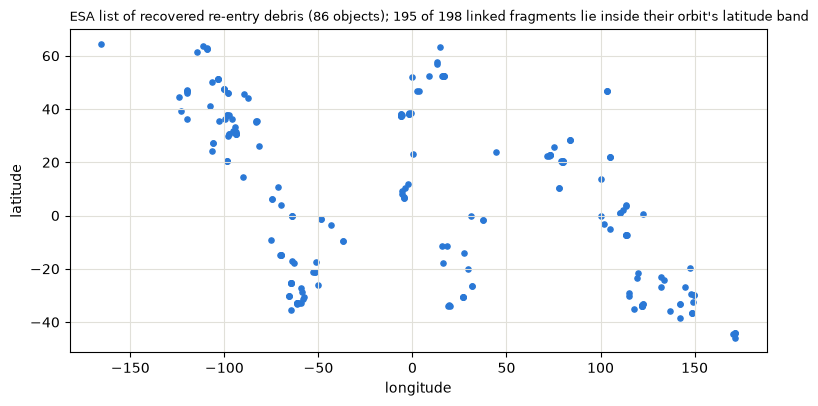

In [19]:
rec = pd.read_csv("../data/feature3_reentry/historical/recovered_debris_esa_with_satcat.csv")
plt.figure(figsize=(9, 4.2)); plt.scatter(rec.lon, rec.lat, s=14, color="#2a78d6")
plt.title(f"ESA list of recovered re-entry debris ({rec.cospar_id.nunique()} objects); "
          f"{int(rec.within_inclination_band.sum())} of {int(rec.INCLINATION.notna().sum())} linked fragments lie inside their orbit's latitude band",
          loc="left", fontsize=9); plt.xlabel("longitude"); plt.ylabel("latitude"); plt.grid(color="#e1e0d9")

## 6. Re-entry — a neural surrogate of the COSMOS propagator (SIM), inside the pipeline

The surrogate replaces the propagator in the Monte Carlo footprint. Samples that leave its training
ranges, or that its ensemble disagrees on, fall back to the reference code. Agreement is with the
COSMOS simulator only, not with real re-entries.

In [20]:
sres = json.load(open("../outputs/benchmarks/reentry_surrogate/results.json"))
print({k: round(v, 3) for k, v in sres["test"].items()}); print("OOD AUROC of ensemble spread:", round(sres["ood_auroc_ensemble_std"], 3))
pd.DataFrame(sres["footprints"])[["alt_km", "cep50_ref_km", "cep50_sur_km", "reference_coverage_of_surrogate_zone", "speedup"]].round(2)

{'n': 40000, 'impacted_fraction': 0.972, 'impact_classification_accuracy': 0.995, 'position_error_km_median': 16.173, 'position_error_km_p95': 69.351, 'downrange_relative_error_median': 0.032, 'fall_time_mae_s': 41.278, 'ensemble_std_km_median': 34.61, 'error_vs_std_spearman': 0.303, 'surrogate_samples_per_s': 80107.299}
OOD AUROC of ensemble spread: 0.726


,alt_km,cep50_ref_km,cep50_sur_km,reference_coverage_of_surrogate_zone,speedup
0,78.76,275.34,269.99,0.97,1087.52
1,63.39,188.35,178.58,0.94,1052.39
2,62.70,187.75,184.88,0.95,936.74
3,91.88,492.98,488.52,0.96,500.32
4,66.12,175.98,182.36,0.95,505.93
5,76.95,333.78,330.91,0.95,662.39
6,69.81,234.13,222.63,0.93,789.28
7,76.15,313.78,313.60,0.98,1266.21
8,80.27,315.02,325.77,0.97,1088.34
9,82.73,327.67,331.63,0.97,1097.56


In [21]:
import time
t0 = time.time(); ref = cosmos.run_pipeline(faults={"Propulsion System": "leak"}, n_samples=600, seed=5); t_ref = time.time() - t0
t0 = time.time(); sur = cosmos.run_pipeline(faults={"Propulsion System": "leak"}, n_samples=600, seed=5, footprint_backend="surrogate"); t_sur = time.time() - t0
print(f"reference {t_ref:.1f} s, surrogate {t_sur:.1f} s; surrogate used for {sur.footprint.surrogate_fraction:.0%} of samples "
      f"(inside training ranges {sur.footprint.inside_training_ranges:.0%}, spread threshold {sur.footprint.spread_threshold_km:.1f} km)")
pd.DataFrame({"reference": ref.footprint.summary(), "surrogate": sur.footprint.summary()})

reference 10.4 s, surrogate 9.1 s; surrogate used for 100% of samples (inside training ranges 100%, spread threshold nan km)


,reference,surrogate
n_impacts,600.000,600.000
downrange_mean_km,1072.400,1082.500
downrange_std_km,724.400,766.200
downrange_min_km,100.500,100.500
downrange_max_km,2790.000,2947.800
downrange_skew,0.738,0.844
cep50_km,588.000,602.700
r95_km,1353.800,1481.400
impact_speed_median_ms,26.000,26.800
max_energy_J,699282.000,741370.000


## 7. The decision layer: combine only compatible, validated evidence

No paired telemetry, imagery and re-entry observations of one object exist, so nothing is trained
jointly across features. The decision layer combines evidence only when the claims are the same,
the object and time window match, the card status is validated, and the input is in-domain.
Otherwise it abstains.

In [22]:
from cosmos.ai.fusion import Evidence, decide, evidence_from_monitor
from cosmos.ai import registry
ev_t = evidence_from_monitor(r_learned.monitor, "learned_monitor", "validated-synthetic", object_id="SIM-SAT-1")
ev_r = Evidence("reentry", "reentry_xgboost", "re-entry within 68 d", 0.7, "validated-real", object_id="NORAD-12345")
print(decide([ev_t, ev_r], "anomalous telemetry", object_id="SIM-SAT-1"))
print(decide([ev_r], "anomalous telemetry", object_id="SIM-SAT-1"))
registry.table()[["name", "feature", "status", "version", "metrics"]]

Decision(claim='anomalous telemetry', probability=0.15475604762965534, abstain=False, reason='combined', used=['learned_monitor'], reported_only=[('reentry_xgboost', 'different claim')], assumptions=['noisy-OR: the evidence items are treated as conditionally independent', 'at least one item is validated on synthetic data only'])
Decision(claim='anomalous telemetry', probability=None, abstain=True, reason='insufficient compatible evidence', used=[], reported_only=[('reentry_xgboost', 'different claim')], assumptions=[])


,name,feature,status,version,metrics
0,esa_conformal_bh_ar8,health,validated-real,ar8/conformal_bh,"{'M1_EW_F0.5_mean': 0.0743509903651713, 'M1_EW..."
1,esa_threshold_ar8,health,validated-real,ar8/threshold,"{'M1_EW_F0.5_mean': 0.0882471881829241, 'M1_EW..."
2,esa_conformal_bh_patchtst,health,validated-real,patchtst/conformal_bh,"{'M1_EW_F0.5_mean': 0.047903460162909604, 'M1_..."
3,esa_threshold_patchtst,health,validated-real,patchtst/threshold,"{'M1_EW_F0.5_mean': 0.06188629692979697, 'M1_E..."
4,esa_conformal_bh_tcn,health,validated-real,tcn/conformal_bh,"{'M1_EW_F0.5_mean': 0.030206357674524533, 'M1_..."
5,esa_threshold_tcn,health,validated-real,tcn/threshold,"{'M1_EW_F0.5_mean': 0.06871064142410953, 'M1_E..."
6,esa_conformal_bh_chronos-bolt-small,health,validated-real,chronos-bolt-small/conformal_bh,"{'M1_EW_F0.5_mean': 0.0238060569496395, 'M1_EW..."
7,esa_threshold_chronos-bolt-small,health,validated-real,chronos-bolt-small/threshold,"{'M1_EW_F0.5_mean': 0.040739522880656, 'M1_EW_..."
8,esa_conformal_bh_persistence,health,validated-real,persistence/conformal_bh,"{'M1_EW_F0.5_mean': 0.0444560535849398, 'M1_EW..."
9,esa_threshold_persistence,health,validated-real,persistence/threshold,"{'M1_EW_F0.5_mean': 0.0444560535849398, 'M1_EW..."


## Summary

Read `outputs/benchmarks/SUMMARY.md` for the component table with every measured number, the
evidence paths and the remaining limitations.